<!-- @format -->

# Variational Auto Encoder


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file()
    and (PROJECT_ROOT / "models" / "mlp_classifier.py").is_file()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: D:\Main\sem5\deep-learning\ASG_2


In [ ]:
import json
import time

import matplotlib.pyplot as plt
import torch
from torch import nn, optim

from data_loader import get_dataloaders
from models.vae import (
    build_vae,
    forward_vae,
)
from utils.metrics import psnr, ssim
from utils.paths import (
    CHECKPOINT_DIR,
    DATA_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    ensure_results_dirs,
    get_device,
)
from utils.reproducibility import set_seed

SEED = 42
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001
LATENT_DIM = 64
BETA = 1.0

DEVICE = get_device()
set_seed(SEED)
ensure_results_dirs()

print(f"Device: {DEVICE}")


Device: xpu


In [4]:
encoder, fc_mu, fc_log_var, decoder = build_vae(latent_dim=LATENT_DIM)

encoder = encoder.to(DEVICE)
fc_mu = fc_mu.to(DEVICE)
fc_log_var = fc_log_var.to(DEVICE)
decoder = decoder.to(DEVICE)

print("VAE components initialized successfully.")


VAE components initialized successfully.


In [6]:
set_seed(SEED)

train_loader, val_loader, test_loader = get_dataloaders(
    root=DATA_DIR, batch_size=BATCH_SIZE, seed=SEED
)

print(f"Training samples: {len(train_loader.dataset)}")
print(f"Validation samples: {len(val_loader.dataset)}")
print(f"Testing samples: {len(test_loader.dataset)}")

images, labels = next(iter(train_loader))

print(f"Image shape: {images.shape}")
print(f"Label shape: {labels.shape}")


Training samples: 56000
Validation samples: 7000
Testing samples: 7000
Image shape: torch.Size([128, 1, 28, 28])
Label shape: torch.Size([128])


In [7]:
sample_images, _ = next(iter(train_loader))
sample_images = sample_images.to(DEVICE)

with torch.no_grad():
    reconstructed, mu, log_var, latent = forward_vae(
        sample_images,
        encoder,
        fc_mu,
        fc_log_var,
        decoder,
    )

print(f"Input shape:         {sample_images.shape}")
print(f"Mu shape:            {mu.shape}")
print(f"Log variance shape:  {log_var.shape}")
print(f"Latent shape:        {latent.shape}")
print(f"Reconstruction:      {reconstructed.shape}")


Input shape:         torch.Size([128, 1, 28, 28])
Mu shape:            torch.Size([128, 64])
Log variance shape:  torch.Size([128, 64])
Latent shape:        torch.Size([128, 64])
Reconstruction:      torch.Size([128, 1, 28, 28])


In [8]:
sample_images, _ = next(iter(train_loader))
sample_images = sample_images.to(DEVICE)

with torch.no_grad():
    reconstructed, mu, log_var, latent = forward_vae(
        sample_images,
        encoder,
        fc_mu,
        fc_log_var,
        decoder,
    )

print(f"Input shape:         {sample_images.shape}")
print(f"Mu shape:            {mu.shape}")
print(f"Log variance shape:  {log_var.shape}")
print(f"Latent shape:        {latent.shape}")
print(f"Reconstruction:      {reconstructed.shape}")


Input shape:         torch.Size([128, 1, 28, 28])
Mu shape:            torch.Size([128, 64])
Log variance shape:  torch.Size([128, 64])
Latent shape:        torch.Size([128, 64])
Reconstruction:      torch.Size([128, 1, 28, 28])


In [9]:
criterion = nn.MSELoss(reduction="mean")

optimizer = optim.Adam(
    list(encoder.parameters())
    + list(fc_mu.parameters())
    + list(fc_log_var.parameters())
    + list(decoder.parameters()),
    lr=LEARNING_RATE,
)


def vae_loss_function(reconstructed, original, mu, log_var, beta=1.0):
    reconstruction_loss = criterion(reconstructed, original)

    kl_divergence = -0.5 * torch.mean(
        torch.sum(
            1 + log_var - mu.pow(2) - log_var.exp(),
            dim=1,
        )
    )

    total_loss = reconstruction_loss + beta * kl_divergence

    return total_loss, reconstruction_loss, kl_divergence


In [10]:
criterion = nn.MSELoss(reduction="mean")

optimizer = optim.Adam(
    list(encoder.parameters())
    + list(fc_mu.parameters())
    + list(fc_log_var.parameters())
    + list(decoder.parameters()),
    lr=LEARNING_RATE,
)


def vae_loss_function(reconstructed, original, mu, log_var, beta=1.0):
    reconstruction_loss = criterion(reconstructed, original)

    kl_divergence = -0.5 * torch.mean(
        torch.sum(
            1 + log_var - mu.pow(2) - log_var.exp(),
            dim=1,
        )
    )

    total_loss = reconstruction_loss + beta * kl_divergence

    return total_loss, reconstruction_loss, kl_divergence


In [11]:
best_val_loss = float("inf")
best_checkpoint_path = CHECKPOINT_DIR / "vae_best.pth"

history = {
    "train_total_loss": [],
    "train_reconstruction_loss": [],
    "train_kl_divergence": [],
    "val_reconstruction_loss": [],
}

for epoch in range(EPOCHS):
    start_time = time.time()

    encoder.train()
    fc_mu.train()
    fc_log_var.train()
    decoder.train()

    train_total = 0.0
    train_reconstruction = 0.0
    train_kl = 0.0
    train_samples = 0

    for images, _ in train_loader:
        images = images.to(DEVICE)

        optimizer.zero_grad()

        reconstructed, mu, log_var, latent = forward_vae(
            images,
            encoder,
            fc_mu,
            fc_log_var,
            decoder,
        )

        total_loss, reconstruction_loss, kl_divergence = vae_loss_function(
            reconstructed,
            images,
            mu,
            log_var,
            beta=BETA,
        )

        total_loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        train_total += total_loss.item() * batch_size
        train_reconstruction += reconstruction_loss.item() * batch_size
        train_kl += kl_divergence.item() * batch_size
        train_samples += batch_size

    train_total /= train_samples
    train_reconstruction /= train_samples
    train_kl /= train_samples

    encoder.eval()
    fc_mu.eval()
    fc_log_var.eval()
    decoder.eval()

    val_reconstruction = 0.0
    val_samples = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(DEVICE)

            reconstructed, mu, log_var, latent = forward_vae(
                images,
                encoder,
                fc_mu,
                fc_log_var,
                decoder,
            )

            batch_size = images.size(0)

            batch_mse = nn.functional.mse_loss(
                reconstructed,
                images,
                reduction="mean",
            )

            val_reconstruction += batch_mse.item() * batch_size
            val_samples += batch_size

    val_reconstruction /= val_samples

    history["train_total_loss"].append(train_total)
    history["train_reconstruction_loss"].append(train_reconstruction)
    history["train_kl_divergence"].append(train_kl)
    history["val_reconstruction_loss"].append(val_reconstruction)

    if val_reconstruction < best_val_loss:
        best_val_loss = val_reconstruction

        torch.save(
            {
                "encoder_state_dict": encoder.state_dict(),
                "fc_mu_state_dict": fc_mu.state_dict(),
                "fc_log_var_state_dict": fc_log_var.state_dict(),
                "decoder_state_dict": decoder.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": epoch + 1,
                "val_reconstruction_loss": best_val_loss,
                "latent_dim": LATENT_DIM,
                "beta": BETA,
                "history": history,
            },
            best_checkpoint_path,
        )

    epoch_time = time.time() - start_time

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Total: {train_total:.6f} | "
        f"Train Recon: {train_reconstruction:.6f} | "
        f"Train KL: {train_kl:.6f} | "
        f"Val Recon: {val_reconstruction:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

print(f"\nBest validation reconstruction MSE: {best_val_loss:.6f}")
print(f"Best checkpoint saved to: {best_checkpoint_path}")


Epoch [01/30] Train Total: 0.095520 | Train Recon: 0.090123 | Train KL: 0.005396 | Val Recon: 0.087293 | Time: 14.25s
Epoch [02/30] Train Total: 0.087580 | Train Recon: 0.087560 | Train KL: 0.000020 | Val Recon: 0.087136 | Time: 11.79s
Epoch [03/30] Train Total: 0.087522 | Train Recon: 0.087516 | Train KL: 0.000006 | Val Recon: 0.086909 | Time: 9.04s
Epoch [04/30] Train Total: 0.087388 | Train Recon: 0.087385 | Train KL: 0.000003 | Val Recon: 0.086919 | Time: 10.67s
Epoch [05/30] Train Total: 0.087359 | Train Recon: 0.087357 | Train KL: 0.000001 | Val Recon: 0.086951 | Time: 9.55s
Epoch [06/30] Train Total: 0.087325 | Train Recon: 0.087324 | Train KL: 0.000001 | Val Recon: 0.086852 | Time: 10.08s
Epoch [07/30] Train Total: 0.087296 | Train Recon: 0.087296 | Train KL: 0.000000 | Val Recon: 0.086898 | Time: 11.85s
Epoch [08/30] Train Total: 0.087270 | Train Recon: 0.087269 | Train KL: 0.000000 | Val Recon: 0.086789 | Time: 11.12s
Epoch [09/30] Train Total: 0.087256 | Train Recon: 0.08725

In [12]:
checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE,
    weights_only=False,
)

encoder.load_state_dict(checkpoint["encoder_state_dict"])
fc_mu.load_state_dict(checkpoint["fc_mu_state_dict"])
fc_log_var.load_state_dict(checkpoint["fc_log_var_state_dict"])
decoder.load_state_dict(checkpoint["decoder_state_dict"])

encoder.eval()
fc_mu.eval()
fc_log_var.eval()
decoder.eval()

print(f"Loaded checkpoint from epoch: {checkpoint['epoch']}")
print(
    f"Best validation reconstruction MSE: {checkpoint['val_reconstruction_loss']:.6f}"
)


Loaded checkpoint from epoch: 25
Best validation reconstruction MSE: 0.086606


In [13]:
test_mse = 0.0
test_psnr = 0.0
test_ssim = 0.0
num_samples = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)

        features = encoder(images)
        mu = fc_mu(features)
        reconstructed = decoder(mu)

        batch_size = images.size(0)

        test_mse += (
            nn.functional.mse_loss(
                reconstructed,
                images,
                reduction="mean",
            ).item()
            * batch_size
        )

        test_psnr += psnr(reconstructed, images).item() * batch_size
        test_ssim += ssim(reconstructed, images).item() * batch_size

        num_samples += batch_size

test_mse /= num_samples
test_psnr /= num_samples
test_ssim /= num_samples

print("VAE Test Results")
print(f"MSE:  {test_mse:.6f}")
print(f"PSNR: {test_psnr:.4f}")
print(f"SSIM: {test_ssim:.4f}")


VAE Test Results
MSE:  0.087502
PSNR: 10.5817
SSIM: 0.1288


In [14]:
all_mu = []
all_log_var = []
total_kl = 0.0
num_samples = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)

        features = encoder(images)
        mu = fc_mu(features)
        log_var = fc_log_var(features)

        kl_divergence = -0.5 * torch.sum(
            1 + log_var - mu.pow(2) - log_var.exp(),
            dim=1,
        )

        all_mu.append(mu.cpu())
        all_log_var.append(log_var.cpu())

        total_kl += kl_divergence.sum().item()
        num_samples += images.size(0)

all_mu = torch.cat(all_mu, dim=0)
all_log_var = torch.cat(all_log_var, dim=0)

latent_mean = all_mu.mean().item()
latent_std = all_mu.std().item()
mean_kl_divergence = total_kl / num_samples

print("VAE Latent Space Analysis")
print(f"Mean latent value:       {latent_mean:.6f}")
print(f"Std latent value:        {latent_std:.6f}")
print(f"Mean KL divergence:      {mean_kl_divergence:.6f}")


VAE Latent Space Analysis
Mean latent value:       0.000003
Std latent value:        0.000203
Mean KL divergence:      0.000001


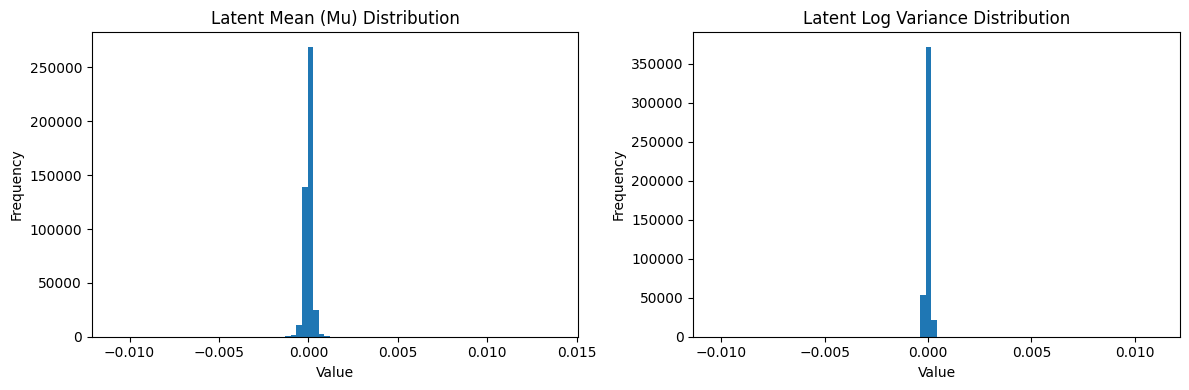

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(all_mu.flatten().numpy(), bins=80)
axes[0].set_title("Latent Mean (Mu) Distribution")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")

axes[1].hist(all_log_var.flatten().numpy(), bins=80)
axes[1].set_title("Latent Log Variance Distribution")
axes[1].set_xlabel("Value")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


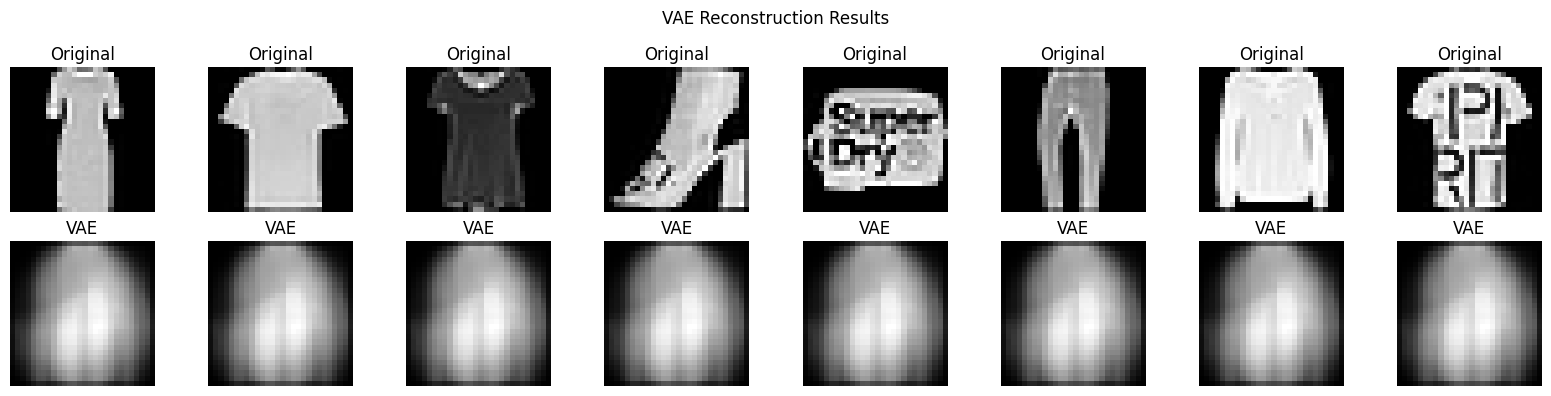

In [16]:
images, _ = next(iter(test_loader))
images = images[:8].to(DEVICE)

with torch.no_grad():
    features = encoder(images)
    mu = fc_mu(features)
    reconstructed = decoder(mu)

images = images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].set_title("VAE")
    axes[1, i].axis("off")

plt.suptitle("VAE Reconstruction Results")
plt.tight_layout()
plt.show()


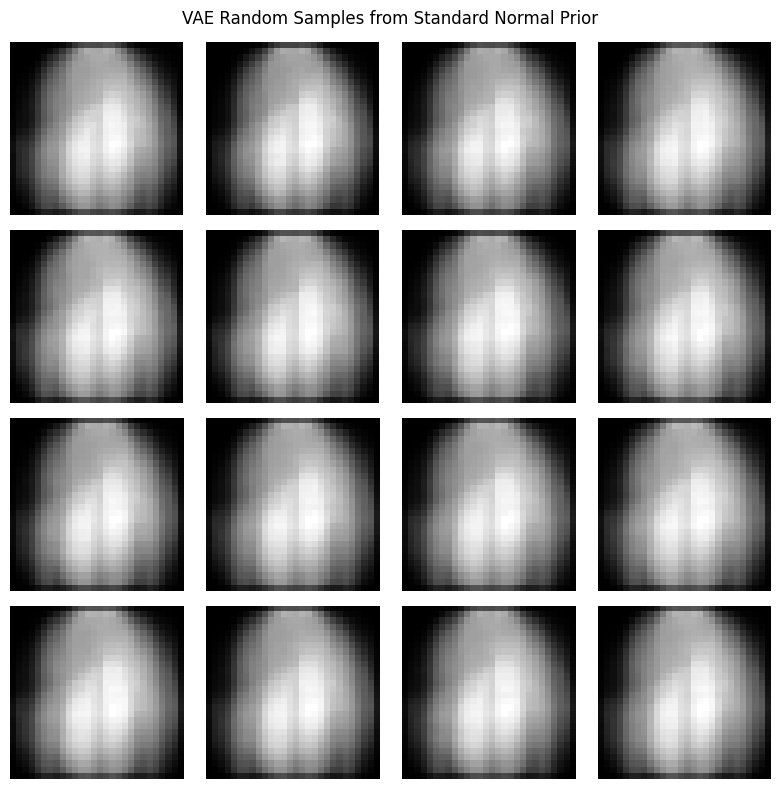

In [17]:
NUM_GENERATED = 16

with torch.no_grad():
    random_latent = torch.randn(
        NUM_GENERATED,
        LATENT_DIM,
        device=DEVICE,
    )

    generated_images = decoder(random_latent)

generated_images = generated_images.cpu()

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("VAE Random Samples from Standard Normal Prior")
plt.tight_layout()
plt.show()


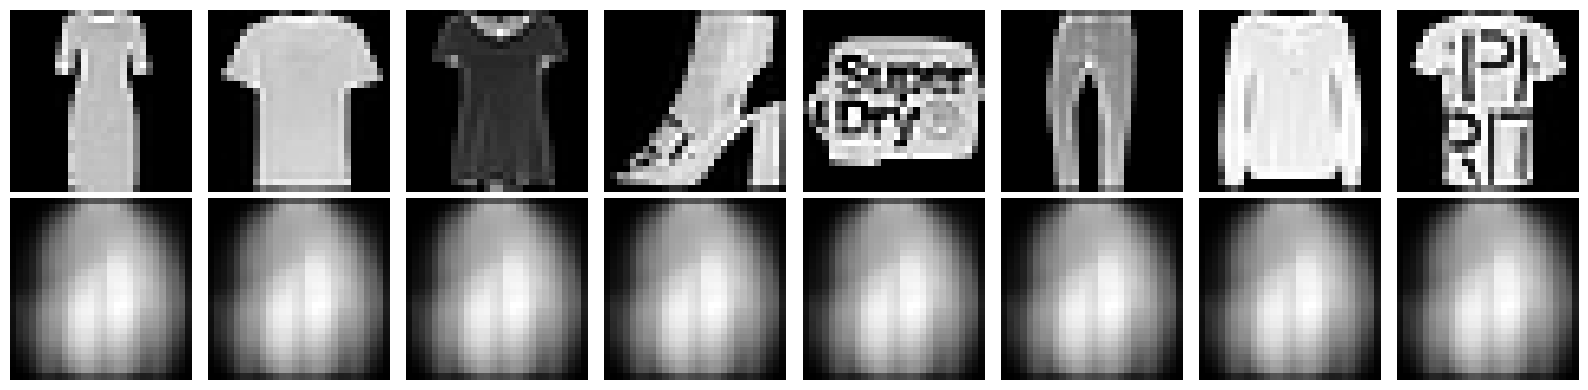

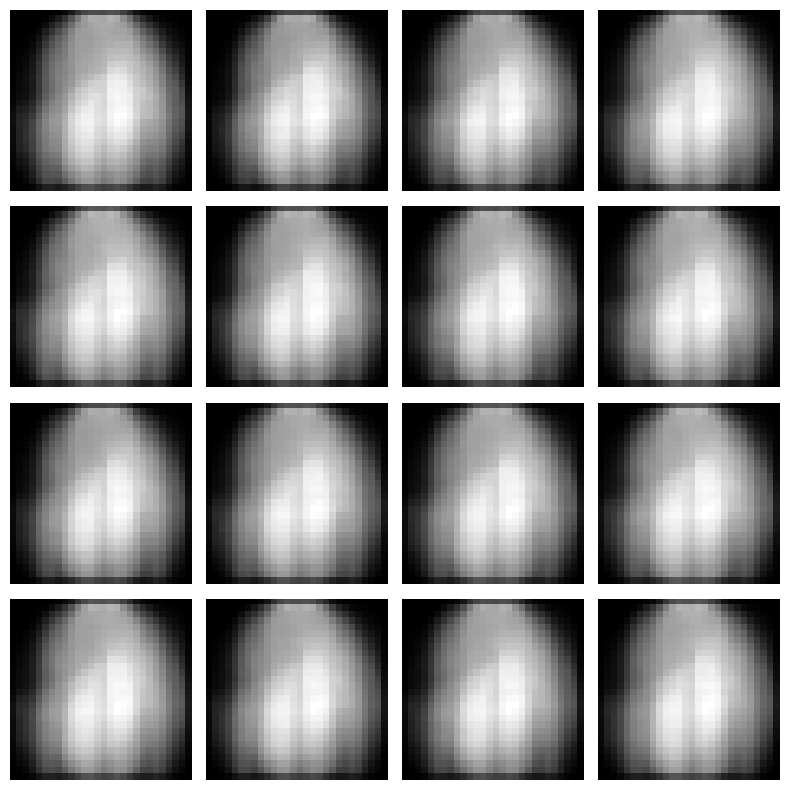

Reconstruction figure: D:\Main\sem5\deep-learning\ASG_2\results\figures\vae_reconstruction.png
Generated samples figure: D:\Main\sem5\deep-learning\ASG_2\results\figures\vae_generated_samples.png


In [18]:
# Save reconstruction figure
reconstruction_path = FIGURES_DIR / "vae_reconstruction.png"

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig(reconstruction_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Save generated samples figure
generation_path = FIGURES_DIR / "vae_generated_samples.png"

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.savefig(generation_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Reconstruction figure: {reconstruction_path}")
print(f"Generated samples figure: {generation_path}")


In [19]:
vae_metrics = {
    "model": "Variational Autoencoder",
    "configuration": {
        "latent_dim": LATENT_DIM,
        "beta": BETA,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "seed": SEED,
    },
    "test_metrics": {
        "mse": test_mse,
        "psnr": test_psnr,
        "ssim": test_ssim,
    },
    "latent_analysis": {
        "mean": latent_mean,
        "std": latent_std,
        "mean_kl_divergence": mean_kl_divergence,
    },
    "training": {
        "best_epoch": checkpoint["epoch"],
        "best_validation_reconstruction_mse": best_val_loss,
        "best_checkpoint": str(best_checkpoint_path.relative_to(PROJECT_ROOT)),
    },
}

metrics_path = METRICS_DIR / "vae.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(vae_metrics, file, indent=4)

print(f"Metrics saved to: {metrics_path}")


Metrics saved to: D:\Main\sem5\deep-learning\ASG_2\results\metrics\vae.json


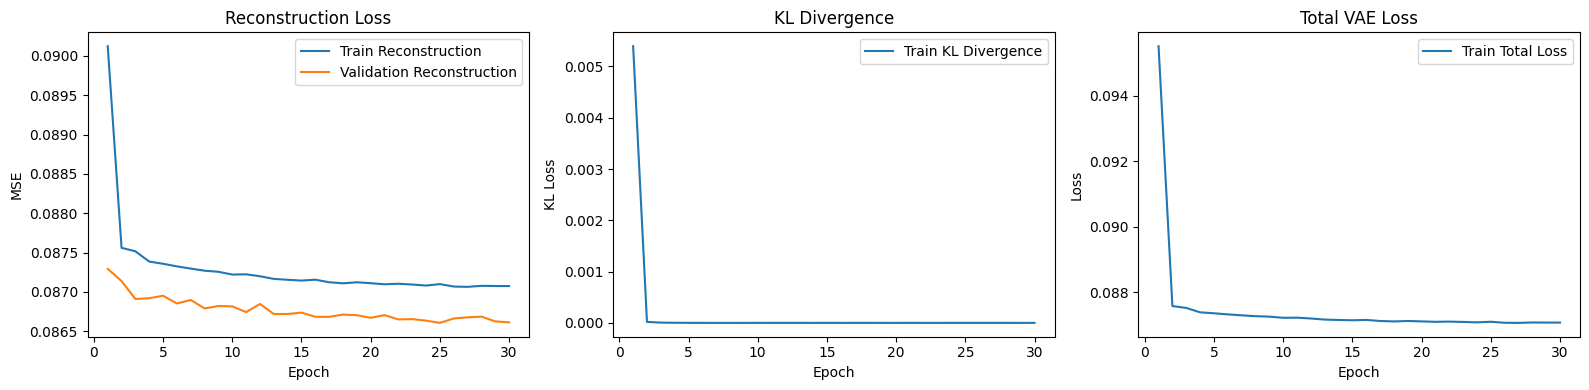

Training curves saved to: D:\Main\sem5\deep-learning\ASG_2\results\figures\vae_training_curves.png


In [20]:
epochs_range = range(1, len(history["train_total_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(
    epochs_range,
    history["train_reconstruction_loss"],
    label="Train Reconstruction",
)
axes[0].plot(
    epochs_range,
    history["val_reconstruction_loss"],
    label="Validation Reconstruction",
)
axes[0].set_title("Reconstruction Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()

axes[1].plot(
    epochs_range,
    history["train_kl_divergence"],
    label="Train KL Divergence",
)
axes[1].set_title("KL Divergence")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("KL Loss")
axes[1].legend()

axes[2].plot(
    epochs_range,
    history["train_total_loss"],
    label="Train Total Loss",
)
axes[2].set_title("Total VAE Loss")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()

plt.tight_layout()

training_curve_path = FIGURES_DIR / "vae_training_curves.png"
plt.savefig(training_curve_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Training curves saved to: {training_curve_path}")
